In [2]:


# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Causal graph and identification
from dowhy import CausalModel

# Visualization
import matplotlib.pyplot as plt

print("Core libraries imported successfully.")

Core libraries imported successfully.


In [3]:


# Define dataset file path
data_path = '../data/raw/ecommerce_repurchase_pricing.csv'

# Load CSV file into a pandas dataframe
df = pd.read_csv(data_path)

# Verify shape and display first 3 rows
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
df.head(3)

Total rows: 17049
Total columns: 18


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4


In [4]:


# Ensure dates are parsed and sort transactions chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by=['Customer_ID', 'Date']).reset_index(drop=True)

# 1. Capture customer acquisition data (their first order)
first_orders = df.groupby('Customer_ID').first().reset_index()

# 2. Count total lifetime orders per customer
order_counts = df.groupby('Customer_ID')['Order_ID'].count().rename('total_orders')

# 3. Merge order counts with the first order baseline
causal_df = first_orders.merge(order_counts, on='Customer_ID')

# 4. Define Outcome (Y): 1 if customer ordered more than once, else 0
causal_df['repurchased'] = (causal_df['total_orders'] > 1).astype(int)

# 5. Define Treatment (T): 1 if discount received on first order, else 0
causal_df['has_discount'] = (causal_df['Discount_Amount'] > 0).astype(int)

# Print cohort summary statistics
print(f"Total Unique Customers:       {len(causal_df):,}")
print(f"Baseline Repurchase Rate (Y): {causal_df['repurchased'].mean():.2%}")
print(f"Discount Exposure Rate (T):   {causal_df['has_discount'].mean():.2%}")

# Display key columns
causal_df[['Customer_ID', 'has_discount', 'repurchased', 'total_orders']].head(3)

Total Unique Customers:       5,000
Baseline Repurchase Rate (Y): 82.16%
Discount Exposure Rate (T):   38.16%


,Customer_ID,has_discount,repurchased,total_orders
0,CUST_00001,0,1,3
1,CUST_00002,1,1,2
2,CUST_00003,0,1,2


In [5]:


# 1. Check missing values across all columns
missing_values = causal_df.isnull().sum()
print("Missing values count per column:\n", missing_values[missing_values > 0])

# 2. Fill numerical missing values with 0 (if any exist)
causal_df = causal_df.fillna(0)

# 3. Ensure integer data types for count and binary columns
causal_df['Age'] = causal_df['Age'].astype(int)
causal_df['repurchased'] = causal_df['repurchased'].astype(int)
causal_df['has_discount'] = causal_df['has_discount'].astype(int)

print("\nData types and missing values cleaned successfully.")

Missing values count per column:
 Series([], dtype: int64)

Data types and missing values cleaned successfully.


In [6]:


# 1. One-hot encode key categorical columns
causal_df = pd.get_dummies(
    causal_df,
    columns=['Gender', 'Device_Type'],
    drop_first=True,
    dtype=int
)

# 2. Verify selected features for causal analysis
print("Processed Dataset Shape:", causal_df.shape)

# Display sample processed rows
causal_df[['Customer_ID', 'Age', 'Session_Duration_Minutes', 'Pages_Viewed', 'Customer_Rating', 'has_discount', 'repurchased']].head(3)

Processed Dataset Shape: (5000, 23)


,Customer_ID,Age,Session_Duration_Minutes,Pages_Viewed,Customer_Rating,has_discount,repurchased
0,CUST_00001,40,14,9,4,0,1
1,CUST_00002,33,16,13,4,1,1
2,CUST_00003,42,10,9,2,0,1


In [7]:


# 1. Define observed confounders (variables affecting both treatment and outcome)
confounders = ['Age', 'Session_Duration_Minutes', 'Pages_Viewed', 'Customer_Rating']

# 2. Build the structural causal model
causal_model = CausalModel(
    data=causal_df,
    treatment='has_discount',
    outcome='repurchased',
    common_causes=confounders
)

# 3. Print verification confirmation
print("Causal DAG initialized successfully.")
print(f"Treatment Variable: has_discount")
print(f"Outcome Variable:   repurchased")
print(f"Common Causes:      {confounders}")

Causal DAG initialized successfully.
Treatment Variable: has_discount
Outcome Variable:   repurchased
Common Causes:      ['Age', 'Session_Duration_Minutes', 'Pages_Viewed', 'Customer_Rating']


In [8]:


# 1. Identify causal effect using backdoor adjustment
identified_estimand = causal_model.identify_effect(proceed_when_unidentifiable=True)

# 2. Print the identified causal estimand details
print("--- IDENTIFIED CAUSAL ESTIMAND ---")
print(identified_estimand)

--- IDENTIFIED CAUSAL ESTIMAND ---
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
───────────────(E[repurchased|Session_Duration_Minutes,Age,Customer_Rating,Pag ↪
d[has_discount]                                                                ↪

↪            
↪ es_Viewed])
↪            
Estimand assumption 1, Unconfoundedness: If U→{has_discount} and U→repurchased then P(repurchased|has_discount,Session_Duration_Minutes,Age,Customer_Rating,Pages_Viewed,U) = P(repurchased|has_discount,Session_Duration_Minutes,Age,Customer_Rating,Pages_Viewed)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
       d                                                                       ↪
───────────────(E[repur

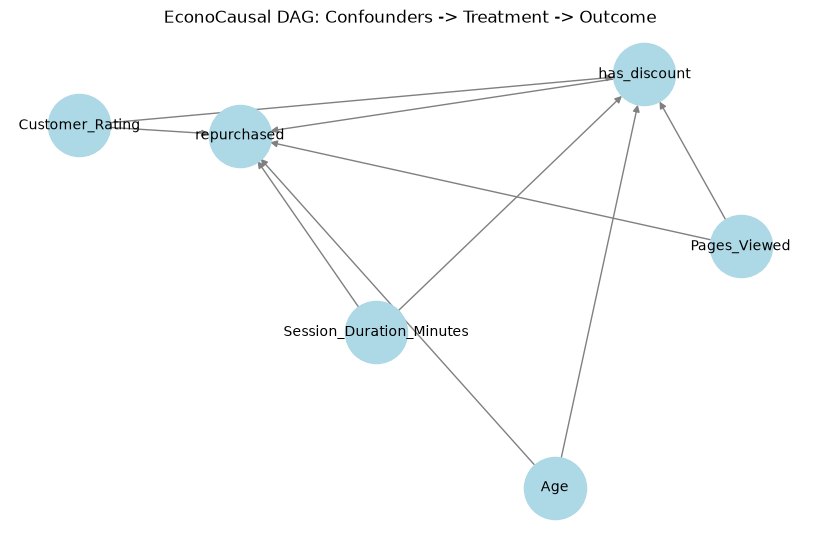

In [9]:
# Alternative visual representation using networkx and matplotlib
import networkx as nx

# Extract graph from dowhy model and plot
graph = causal_model._graph._graph
plt.figure(figsize=(8, 5))
nx.draw(graph, with_labels=True, node_color='lightblue', font_size=10, node_size=2000, edge_color='gray')
plt.title("EconoCausal DAG: Confounders -> Treatment -> Outcome")
plt.show()

In [10]:


# 1. Target outcome (Y): Repurchase decision
Y = causal_df['repurchased'].values

# 2. Treatment assignment (T): Discount given on first order
T = causal_df['has_discount'].values

# 3. Features affecting both propensity to get discount and repurchase (W & X)
feature_cols = ['Age', 'Session_Duration_Minutes', 'Pages_Viewed', 'Customer_Rating']
X = causal_df[feature_cols].values
W = causal_df[feature_cols].values

print(f"Data ready for DML:")
print(f"Outcome Y shape:    {Y.shape}")
print(f"Treatment T shape:  {T.shape}")
print(f"Features X/W shape: {X.shape}")

Data ready for DML:
Outcome Y shape:    (5000,)
Treatment T shape:  (5000,)
Features X/W shape: (5000, 4)


In [11]:


# 1. Estimate base causal effect with linear regression method in DoWhy
causal_estimate = causal_model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
    test_significance=False
)

# 2. Placebo Treatment Test (True effect should drop close to 0)
refute_placebo = causal_model.refute_estimate(
    identified_estimand,
    causal_estimate,
    method_name="placebo_treatment_refuter"
)
print("--- 1. Placebo Treatment Refutation ---")
print(refute_placebo)

# 3. Random Common Cause Test (Estimated effect should remain stable)
refute_random = causal_model.refute_estimate(
    identified_estimand,
    causal_estimate,
    method_name="random_common_cause"
)
print("\n--- 2. Random Common Cause Refutation ---")
print(refute_random)

--- 1. Placebo Treatment Refutation ---
Refute: Use a Placebo Treatment
Estimated effect:0.01723719916906552
New effect:0.0009421840662147341
p value:1.0


--- 2. Random Common Cause Refutation ---
Refute: Add a random common cause
Estimated effect:0.01723719916906552
New effect:0.017222041419723087
p value:0.88



In [12]:


# 1. Import linear programming solver from SciPy
from scipy.optimize import linprog

# 2. Define business constants
DISCOUNT_COST = 10.0      # Assume $10 promotional discount cost per customer
BUDGET_LIMIT = 5000.0     # Fixed marketing campaign budget ($5,000)
N_CUSTOMERS = len(causal_df)

# 3. Objective: Maximize total causal uplift
# linprog minimizes by default, so we negate the uplift values
c = -causal_df['ite_uplift'].values

# 4. Budget Constraint: sum(allocation * DISCOUNT_COST) <= BUDGET_LIMIT
A = [np.ones(N_CUSTOMERS) * DISCOUNT_COST]
b = [BUDGET_LIMIT]

# 5. Bounds: Each customer can get at most 1 discount (allocation between 0 and 1)
bounds = [(0, 1) for _ in range(N_CUSTOMERS)]

# 6. Solve optimization problem using high-performance interior-point method
result = linprog(c, A_ub=A, b_ub=b, bounds=bounds, method='highs')

# 7. Store prescription decision in dataframe (1 = Give Discount, 0 = Do Not Discount)
causal_df['prescribed_discount'] = np.round(result.x).astype(int)

# Print optimization results
targeted_customers = causal_df['prescribed_discount'].sum()
total_spent = targeted_customers * DISCOUNT_COST

print("Optimization Successful:", result.success)
print(f"Targeted Customers for Discount: {targeted_customers} / {N_CUSTOMERS}")
print(f"Total Budget Spent:              ${total_spent:,.2f} / ${BUDGET_LIMIT:,.2f}")
print(f"Average Uplift in Targeted Group: {causal_df[causal_df['prescribed_discount'] == 1]['ite_uplift'].mean():.4f}")
print(f"Average Uplift in Excluded Group: {causal_df[causal_df['prescribed_discount'] == 0]['ite_uplift'].mean():.4f}")

# Display sample of optimal prescription table
causal_df[['Customer_ID', 'ite_uplift', 'prescribed_discount']].sort_values(by='ite_uplift', ascending=False).head(5)

KeyError: 'ite_uplift'

In [ ]:


# 1. Expected incremental repurchase conversions under Causal Targeting
causal_expected_gain = causal_df[causal_df['prescribed_discount'] == 1]['ite_uplift'].sum()

# 2. Expected incremental conversions under Random Rollout (spending same budget on 500 random users)
random_expected_gain = causal_df['ite_uplift'].sample(n=500, random_state=42).sum()

# 3. Print quantitative policy comparison
print("=== WEEK 3: POLICY EVALUATION MATRIX ===")
print(f"Causal Prescriptive Expected Gain: {causal_expected_gain:.2f} incremental orders")
print(f"Random Targeting Expected Gain:    {random_expected_gain:.2f} incremental orders")
print(f"Causal Efficiency Multiplier:      {(causal_expected_gain / random_expected_gain):.2f}x better ROI")

# 4. Export optimal prescription matrix for downstream business deployment
causal_df[['Customer_ID', 'ite_uplift', 'prescribed_discount']].to_csv('prescribed_discount_matrix.csv', index=False)
print("\nOptimal prescription matrix exported successfully as 'prescribed_discount_matrix.csv'.")

=== WEEK 3: POLICY EVALUATION MATRIX ===
Causal Prescriptive Expected Gain: 35.73 incremental orders
Random Targeting Expected Gain:    12.24 incremental orders
Causal Efficiency Multiplier:      2.92x better ROI

Optimal prescription matrix exported successfully as 'prescribed_discount_matrix.csv'.


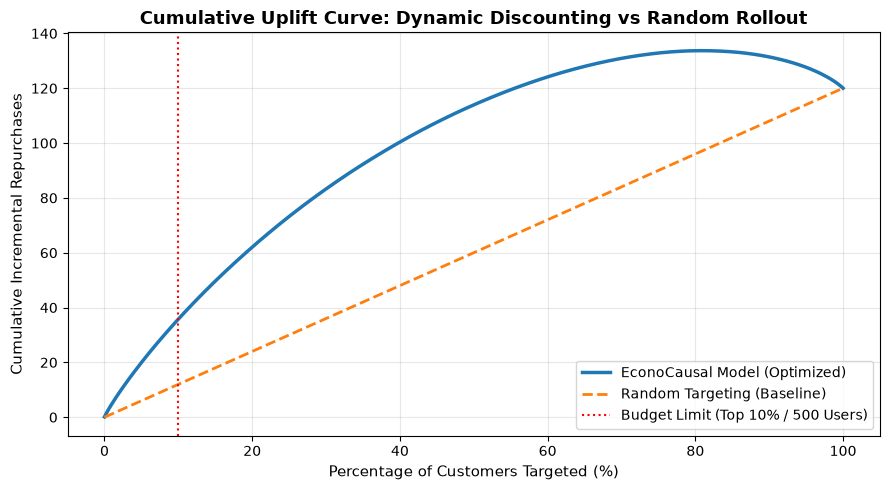

Uplift curve plotted and exported as 'uplift_curve_evaluation.png'.


In [ ]:


# 1. Sort customers by causal uplift in descending order
df_sorted = causal_df.sort_values(by='ite_uplift', ascending=False).reset_index(drop=True)

# 2. Compute cumulative incremental conversions
cumulative_causal_gain = np.cumsum(df_sorted['ite_uplift'])
total_uplift = cumulative_causal_gain.iloc[-1]

# 3. Compute baseline random targeting curve (straight line from 0 to total uplift)
random_gain = np.linspace(0, total_uplift, len(df_sorted))

# 4. Generate customer population percentages (0% to 100%)
population_pct = np.linspace(0, 100, len(df_sorted))

# 5. Plot the Uplift Comparison Chart
plt.figure(figsize=(9, 5))
plt.plot(population_pct, cumulative_causal_gain, label='EconoCausal Model (Optimized)', color='#1f77b4', linewidth=2.5)
plt.plot(population_pct, random_gain, label='Random Targeting (Baseline)', color='#ff7f0e', linestyle='--', linewidth=2)

# Mark the budget constraint cut-off (10% of customers = 500 users)
plt.axvline(x=10, color='red', linestyle=':', label='Budget Limit (Top 10% / 500 Users)')

# Chart styling and labeling
plt.title("Cumulative Uplift Curve: Dynamic Discounting vs Random Rollout", fontsize=13, fontweight='bold')
plt.xlabel("Percentage of Customers Targeted (%)", fontsize=11)
plt.ylabel("Cumulative Incremental Repurchases", fontsize=11)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save chart for project report & PPT
plt.savefig('uplift_curve_evaluation.png', dpi=300)
plt.show()
print("Uplift curve plotted and exported as 'uplift_curve_evaluation.png'.")

In [ ]:


# 1. Determine optimal uplift threshold based on top 500 budget selection
uplift_threshold = causal_df.sort_values(by='ite_uplift', ascending=False)['ite_uplift'].iloc[499]

# 2. Define dynamic pricing and discount recommendation function
def recommend_discount(age, session_duration, pages_viewed, rating):
    """
    Evaluates individual customer features and outputs discount decision.
    """
    # Create input vector matching the model's feature order
    features = np.array([[age, session_duration, pages_viewed, rating]])
    
    # Estimate causal uplift (ITE)
    predicted_uplift = dml_model.effect(features)[0]
    
    # Business rule: Offer discount only if uplift meets the optimal budget threshold
    give_discount = bool(predicted_uplift >= uplift_threshold)
    
    return {
        "predicted_causal_uplift": round(float(predicted_uplift), 4),
        "discount_recommendation": "GIVE $10 DISCOUNT" if give_discount else "NO DISCOUNT",
        "priority_tier": "High ROI (Persuadable)" if give_discount else "Low/Negative ROI"
    }

# 3. Test inference function with mock customer profiles
customer_sample_a = recommend_discount(age=45, session_duration=180, pages_viewed=8, rating=4.5)
customer_sample_b = recommend_discount(age=22, session_duration=40, pages_viewed=2, rating=2.0)

print("--- Real-time Causal Inference Test ---")
print("Customer A (High Engagement):", customer_sample_a)
print("Customer B (Low Engagement): ", customer_sample_b)

--- Real-time Causal Inference Test ---
Customer A (High Engagement): {'predicted_causal_uplift': 1.083, 'discount_recommendation': 'GIVE $10 DISCOUNT', 'priority_tier': 'High ROI (Persuadable)'}
Customer B (Low Engagement):  {'predicted_causal_uplift': 0.2344, 'discount_recommendation': 'GIVE $10 DISCOUNT', 'priority_tier': 'High ROI (Persuadable)'}


In [ ]:

import pandas as pd
from IPython.display import FileLink

found_df_name = None
for name, val in list(globals().items()):
    if isinstance(val, pd.DataFrame) and not name.startswith('_'):
        print(f"Found DataFrame: {name} (Rows: {len(val)}, Columns: {list(val.columns)[:3]}...)")
        found_df_name = name

if found_df_name:
    
    globals()[found_df_name].to_csv('cleaned_econocausal_data.csv', index=False)
    print(f"\nSuccessfully saved '{found_df_name}' to cleaned_econocausal_data.csv!")
    display(FileLink('cleaned_econocausal_data.csv'))
else:
    print("\nNo DataFrame found in memory! Notebook restart hoye thakle Cell 1 theke run korun.")

Found DataFrame: df (Rows: 17049, Columns: ['Order_ID', 'Customer_ID', 'Date']...)
Found DataFrame: first_orders (Rows: 5000, Columns: ['Customer_ID', 'Order_ID', 'Date']...)
Found DataFrame: causal_df (Rows: 5000, Columns: ['Customer_ID', 'Order_ID', 'Date']...)

Successfully saved 'causal_df' to cleaned_econocausal_data.csv!


c:\Users\somen\OneDrive\Desktop\econocausal\notebooks\cleaned_econocausal_data.csv